# Revenue Leakage Analysis
Exploratory analysis of the reconciliation results, using the `reporting` schema (the same data Power BI reads).

**Definitions.** *Revenue leakage* is unique underbilling: Σ max(0, expected − invoiced) over in-scope obligations, taken from the latest full-scope audit per month. Exception exposure can overlap between categories, so it is never added up to get leakage.

**Data.** The demo database contains **synthetic data** with planted anomalies. Nothing here represents real recovered revenue.

In [1]:
import os, pandas as pd, matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
# Read-only analysis. Set DATABASE_URL (e.g. the powerbi_reader role) before running; never hard-code credentials.
engine = create_engine(os.environ["DATABASE_URL"], connect_args={"options": "-c TimeZone=UTC"})
q = lambda sql, **p: pd.read_sql(text(sql), engine, params=p)
plt.rcParams.update({"figure.facecolor": "#050b1c", "axes.facecolor": "#0b1330", "axes.edgecolor": "#1e2c5a", "text.color": "#e6ecff",
                     "axes.labelcolor": "#e6ecff", "xtick.color": "#8b98bd", "ytick.color": "#8b98bd", "figure.figsize": (10, 4)})
pd.options.display.float_format = "{:,.2f}".format

## 1. Validation: the reporting views reconcile to the stored audits

In [2]:
chk = q("""SELECT a.run_code, a.underbilled_total AS audit_leakage, SUM(f.underbilled_amount) AS view_leakage,
                 a.overbilled_total AS audit_over, SUM(f.overbilled_amount) AS view_over
          FROM reporting.latest_audit a JOIN reporting.fact_reconciliation f USING (audit_run_id) GROUP BY 1,2,4 ORDER BY 1""")
chk["leakage_ok"] = chk.audit_leakage == chk.view_leakage
chk["over_ok"] = chk.audit_over == chk.view_over
assert chk.leakage_ok.all() and chk.over_ok.all(), "reporting views disagree with stored audits"
chk

,run_code,audit_leakage,view_leakage,audit_over,view_over,leakage_ok,over_ok
0,AUD-202605-0001,"14,925.00","14,925.00",0.00,0.00,True,True
1,AUD-202606-0002,"29,745.00","29,745.00",0.00,0.00,True,True
2,AUD-202607-0003,"25,500.00","25,500.00",0.00,0.00,True,True
3,AUD-202608-0004,"38,481.00","38,481.00",0.00,0.00,True,True
4,AUD-202609-0005,"33,367.00","33,367.00",0.00,0.00,True,True
5,AUD-202610-0006,"155,300.00","155,300.00","276,027.50","276,027.50",True,True


## 2. Leakage trend

,month,run_code,expected,leakage,overbilling,reconciliation_rate_pct
0,2026-05-01,AUD-202605-0001,"11,061,776.34","14,925.00",0.00,99.60
1,2026-06-01,AUD-202606-0002,"11,156,734.78","29,745.00",0.00,99.42
2,2026-07-01,AUD-202607-0003,"11,920,297.06","25,500.00",0.00,99.44
3,2026-08-01,AUD-202608-0004,"11,419,808.55","38,481.00",0.00,99.25
4,2026-09-01,AUD-202609-0005,"11,631,331.28","33,367.00",0.00,99.26
5,2026-10-01,AUD-202610-0006,"12,582,287.31","155,300.00","276,027.50",97.27


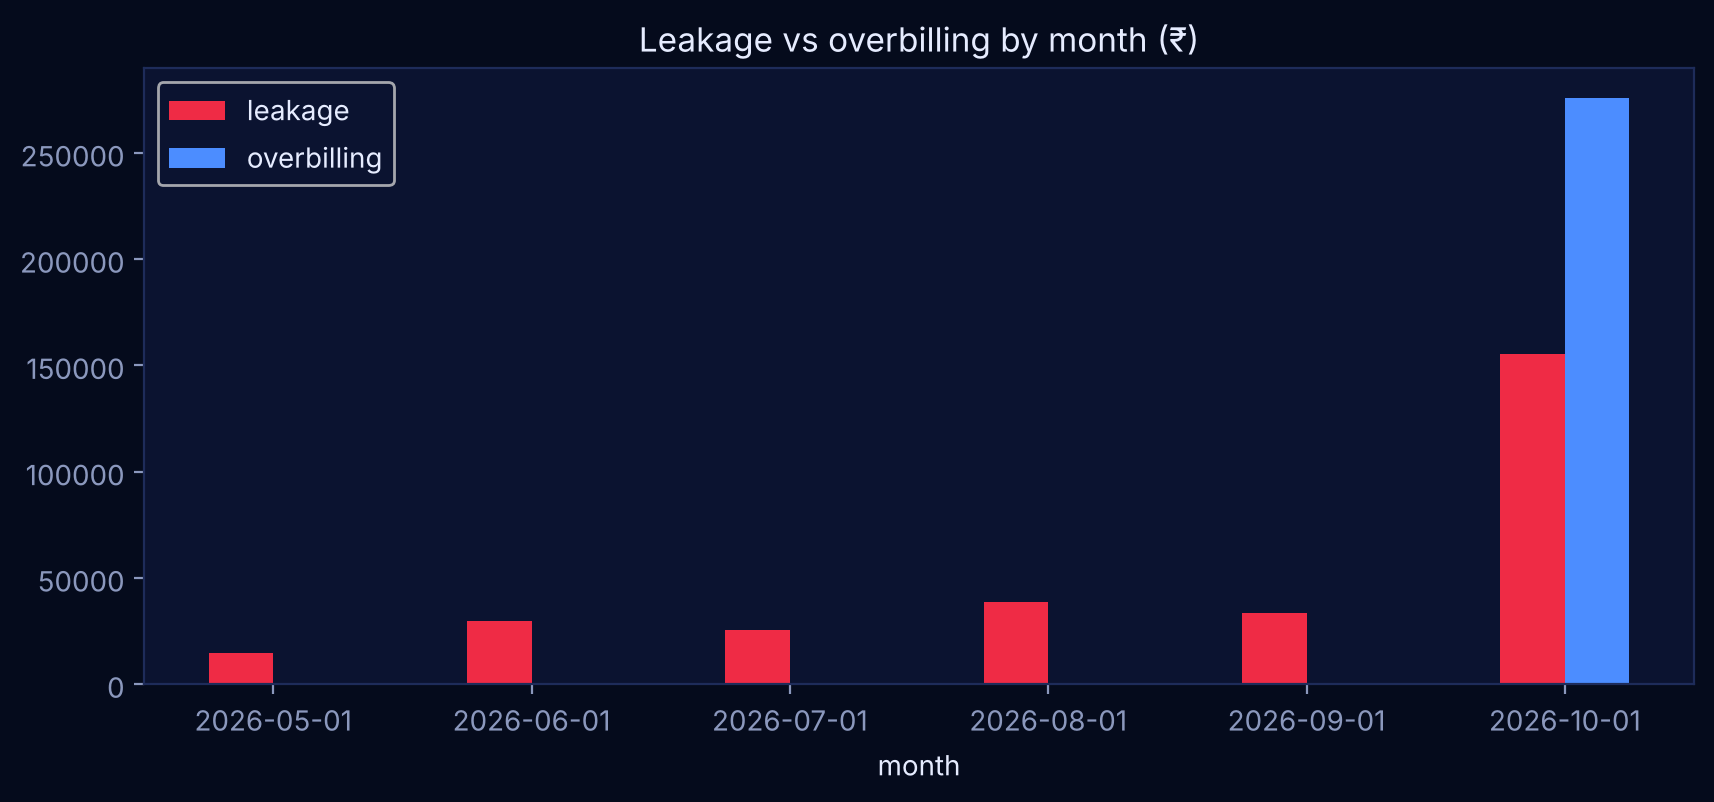

In [3]:
trend = q(open("../sql/01_leakage_trend.sql").read())
ax = trend.plot(x="month", y=["leakage", "overbilling"], kind="bar", color=["#ef2b45", "#4c8dff"], rot=0, title="Leakage vs overbilling by month (₹)")
trend[["month", "run_code", "expected", "leakage", "overbilling", "reconciliation_rate_pct"]]

In [4]:
t = trend.set_index("month")
mom = (t.leakage.pct_change() * 100).round(1)
print("Month-over-month leakage change (%):"); print(mom.dropna().to_string())
print(f"\nLatest month leakage is {t.leakage.iloc[-1] / t.leakage.iloc[:-1].mean():.1f}x the prior-month average.")

Month-over-month leakage change (%):
month
2026-06-01    99.30
2026-07-01   -14.30
2026-08-01    50.90
2026-09-01   -13.30
2026-10-01   365.40

Latest month leakage is 5.5x the prior-month average.


## 3. Where the latest month's leakage sits (Pareto)

In [5]:
par = q(open("../sql/02_leakage_pareto.sql").read())
n80 = int((par.cumulative_pct < 80).sum()) + 1
print(f"{n80} of {len(par)} underbilled customers account for ≥80% of leakage.")
par.head(10)

4 of 8 underbilled customers account for ≥80% of leakage.


,customer_name,segment,leakage,cumulative_pct
0,TechNova Pvt. Ltd.,ENTERPRISE,"60,000.00",38.60
1,DataCrest Technologies,ENTERPRISE,"33,950.00",60.50
2,Kestrel Logistics Pvt. Ltd.,MID_MARKET,"24,000.00",75.90
3,Crest Networks,ENTERPRISE,"22,800.00",90.60
4,Quill Data LLP,MID_MARKET,"6,000.00",94.50
5,InfiniIT Services,ENTERPRISE,"4,950.00",97.70
6,Quanta Logistics Inc.,MID_MARKET,"2,160.00",99.10
7,Lumen Media,MID_MARKET,"1,440.00",100.00


In [6]:
by_status = q("""SELECT status, COUNT(*) AS obligations, SUM(underbilled_amount) AS leakage, SUM(overbilled_amount) AS overbilling
                FROM reporting.fact_reconciliation WHERE audit_period_start = (SELECT max(period_start) FROM reporting.latest_audit)
                GROUP BY 1 ORDER BY leakage DESC""")
by_status

,status,obligations,leakage,overbilling
0,UNDERBILLED,5,"91,350.00",0.00
1,MISSING_CHARGE,3,"63,950.00",0.00
2,EXCLUDED,10,0.00,0.00
3,OVERBILLED,8,0.00,"276,027.50"
4,MATCHED,571,0.00,0.00


## 4. Exceptions by category
Category exposure is shown for triage. It is **not** additive into leakage.

,category,total,open,resolved,avg_days_to_resolve,exposure,leakage_counting_exposure
0,PAYMENT_DISCREPANCY,3,3,0,None,"146,921.32",NaN
1,DUPLICATE_INVOICE,1,1,0,None,"144,805.00",NaN
2,PRICING_MISMATCH,5,5,0,None,"137,808.00","16,518.00"
3,UNDERBILLING,8,8,0,None,"99,450.00","99,450.00"
4,MISSING_CHARGE,7,7,0,None,"78,000.00","78,000.00"
5,UNBILLED_USAGE,3,3,0,None,"54,225.00","54,225.00"
6,DISCOUNT_DRIFT,3,3,0,None,"49,125.00","49,125.00"
7,OVERBILLING,2,2,0,None,"9,932.50",NaN


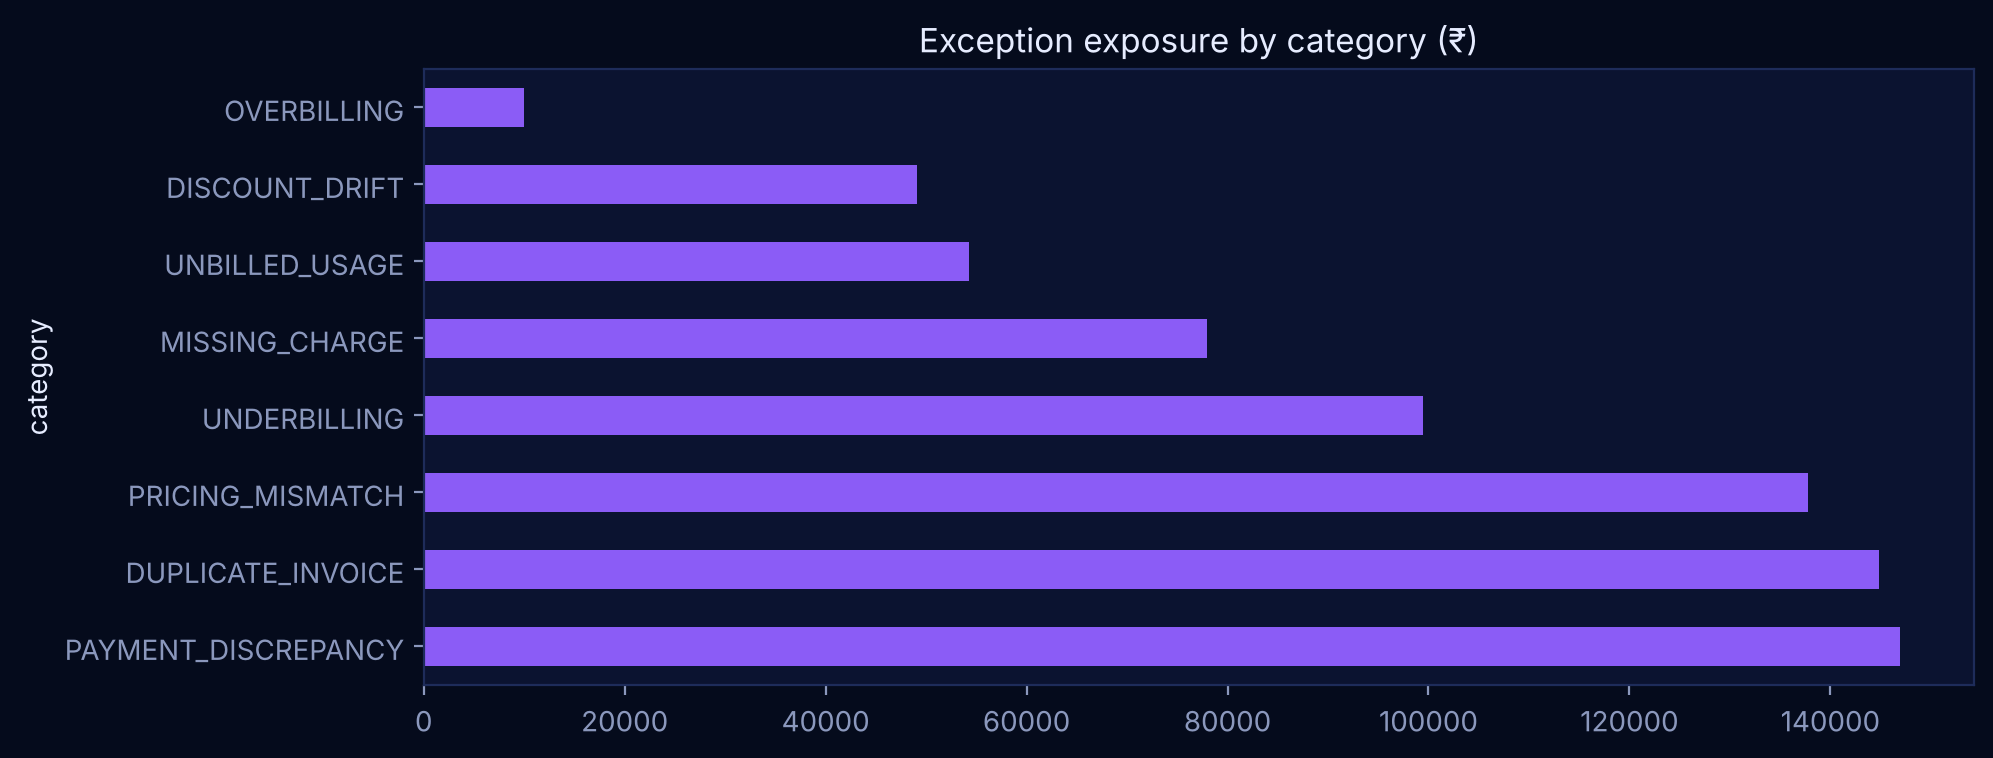

In [7]:
ex = q(open("../sql/05_exception_resolution.sql").read())
ex.plot(x="category", y="exposure", kind="barh", color="#8b5cf6", legend=False, title="Exception exposure by category (₹)")
ex

## 5. Findings (computed above)
- The per-month reconciliation check passes: the views equal the stored audits exactly.
- The trend and Pareto cells above give the month-over-month change and the customer concentration. Investigate the top customers on the Exceptions page, which shows the evidence for each case.
- Payment discrepancies and duplicate invoices are listed for triage, but they are excluded from leakage because they are not underbilling.